In [ ]:
!pip install librosa soundfile scikit-learn seaborn matplotlib pandas numpy

In [ ]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import librosa.display
import soundfile as sf

from IPython.display import Audio
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

print("All libraries imported!")

All libraries imported!


In [ ]:
print("Numpy version: ",np.__version__)
print("Pandas version: ",pd.__version__)
print("Seaborn version: ",sns.__version__)
print("Librosa version: ",librosa.__version__)
print("Soundfile version: ",sf.__version__)

print("GPU available:", len(__import__("tensorflow").config.list_physical_devices("GPU")) > 0)

Numpy version:  2.1.3
Pandas version:  2.2.3
Seaborn version:  0.13.2
Librosa version:  0.11.0
Soundfile version:  0.14.0
GPU available: False


In [ ]:
import zipfile

zip_path ="/content/Audio_Speech_Actors_01-24.zip"
extracted_path = "/content/ravdess"

os.makedirs(extracted_path,exist_ok=True)

with zipfile.ZipFile(zip_path,'r') as zip_ref:
  zip_ref.extractall(extracted_path)
  print("Dataset extracted successfully!")

Dataset extracted successfully!


In [ ]:

import glob
import os

audio_files = glob.glob(
    os.path.join(extracted_path, "**", "*.wav"),
    recursive=True
)

print("Total audio files:", len(audio_files))
print("Actor folders:", len([
    folder for folder in os.listdir(extracted_path)
    if os.path.isdir(os.path.join(extracted_path, folder))
]))

print("\nSample files:")
for file in audio_files[:5]:
    print(file)


Total audio files: 1440
Actor folders: 24

Sample files:
/content/ravdess/Actor_09/03-01-02-01-01-01-09.wav
/content/ravdess/Actor_09/03-01-08-01-02-01-09.wav
/content/ravdess/Actor_09/03-01-06-02-01-02-09.wav
/content/ravdess/Actor_09/03-01-07-02-01-02-09.wav
/content/ravdess/Actor_09/03-01-07-01-01-02-09.wav


In [ ]:
emotion_mapping  = {
    "01":"neutral",
    "02":"calm",
    "03":"happy",
    "04":"sad",
    "05":"angry",
    "06":"fearful",
    "07":"disgust",
    "08":"surprised"
}

print("Emotion mapping :",len(emotion_mapping))

for code ,emotion in emotion_mapping.items():
  print(code,":",emotion)

Emotion mapping : 8
01 : neutral
02 : calm
03 : happy
04 : sad
05 : angry
06 : fearful
07 : disgust
08 : surprised


In [ ]:
import librosa

def load_audio(file_path):
    audio, sample_rate = librosa.load(
        file_path,
        sr=None,
        mono=True
    )
    return audio, sample_rate

In [ ]:


def plot_waveform(audio, sample_rate, title="Audio Waveform"):
    time = np.arange(len(audio)) / sample_rate

    plt.figure(figsize=(12, 4))
    plt.plot(time, audio)
    plt.xlabel("Time (s)")
    plt.ylabel("Amplitude")
    plt.title(title)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

Audio shape: (160160,)
Sample rate: 48000
Duration: 3.3366666666666664 seconds


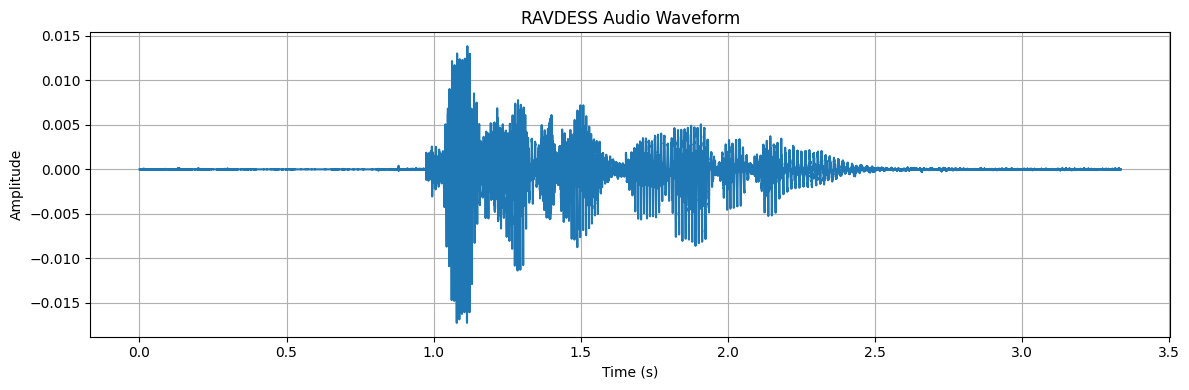

In [ ]:
audio, sample_rate = load_audio(audio_files[0])

print("Audio shape:", audio.shape)
print("Sample rate:", sample_rate)
print("Duration:", len(audio) / sample_rate, "seconds")

plot_waveform(
    audio,
    sample_rate,
    title="RAVDESS Audio Waveform"
)

In [ ]:


data = []

for file_path in audio_files:
    filename = os.path.basename(file_path)
    parts = filename.replace(".wav", "").split("-")

    emotion_code = parts[2]
    actor = parts[6]

    data.append({
        "file_path": file_path,
        "emotion_code": emotion_code,
        "emotion": emotion_mapping[emotion_code],
        "actor": int(actor)
    })

df = pd.DataFrame(data)

print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())

print("\nEmotion distribution:")
print(df["emotion"].value_counts())

Dataset shape: (1440, 4)

First 5 rows:
                                           file_path emotion_code    emotion  \
0  /content/ravdess/Actor_09/03-01-02-01-01-01-09...           02       calm   
1  /content/ravdess/Actor_09/03-01-08-01-02-01-09...           08  surprised   
2  /content/ravdess/Actor_09/03-01-06-02-01-02-09...           06    fearful   
3  /content/ravdess/Actor_09/03-01-07-02-01-02-09...           07    disgust   
4  /content/ravdess/Actor_09/03-01-07-01-01-02-09...           07    disgust   

   actor  
0      9  
1      9  
2      9  
3      9  
4      9  

Emotion distribution:
emotion
calm         192
surprised    192
fearful      192
disgust      192
sad          192
happy        192
angry        192
neutral       96
Name: count, dtype: int64


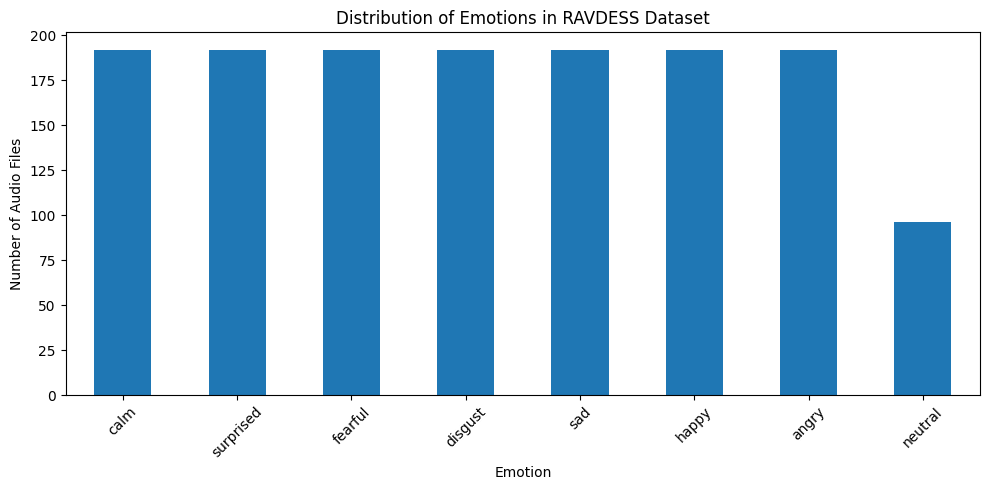

In [ ]:
import matplotlib.pyplot as plt

emotion_counts = df["emotion"].value_counts()

plt.figure(figsize=(10, 5))
emotion_counts.plot(kind="bar")

plt.title("Distribution of Emotions in RAVDESS Dataset")
plt.xlabel("Emotion")
plt.ylabel("Number of Audio Files")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate file paths:", df["file_path"].duplicated().sum())

print("\nUnique actors:", df["actor"].nunique())

Missing values:
file_path       0
emotion_code    0
emotion         0
actor           0
dtype: int64

Duplicate file paths: 0

Unique actors: 24
